In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("bumble.csv")

In [4]:
df.head()

,age,status,gender,body_type,diet,drinks,education,ethnicity,height,income,job,last_online,location,pets,religion,sign,speaks
0,22,single,m,a little extra,strictly anything,socially,working on college/university,"asian, white",75.0,-1,transportation,2012-06-28-20-30,"south san francisco, california",likes dogs and likes cats,agnosticism and very serious about it,gemini,english
1,35,single,m,average,mostly other,often,working on space camp,white,70.0,80000,hospitality / travel,2012-06-29-21-41,"oakland, california",likes dogs and likes cats,agnosticism but not too serious about it,cancer,"english (fluently), spanish (poorly), french (..."
2,38,available,m,thin,anything,socially,graduated from masters program,NaN,68.0,-1,NaN,2012-06-27-09-10,"san francisco, california",has cats,NaN,pisces but it doesn&rsquo;t matter,"english, french, c++"
3,23,single,m,thin,vegetarian,socially,working on college/university,white,71.0,20000,student,2012-06-28-14-22,"berkeley, california",likes cats,NaN,pisces,"english, german (poorly)"
4,29,single,m,athletic,NaN,socially,graduated from college/university,"asian, black, other",66.0,-1,artistic / musical / writer,2012-06-27-21-26,"san francisco, california",likes dogs and likes cats,NaN,aquarius,english


In [5]:
df.shape

(59946, 17)

In [6]:
df.columns

Index(['age', 'status', 'gender', 'body_type', 'diet', 'drinks', 'education',
       'ethnicity', 'height', 'income', 'job', 'last_online', 'location',
       'pets', 'religion', 'sign', 'speaks'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   status       59946 non-null  object 
 2   gender       59946 non-null  object 
 3   body_type    54650 non-null  object 
 4   diet         35551 non-null  object 
 5   drinks       56961 non-null  object 
 6   education    53318 non-null  object 
 7   ethnicity    54266 non-null  object 
 8   height       59943 non-null  float64
 9   income       59946 non-null  int64  
 10  job          51748 non-null  object 
 11  last_online  59946 non-null  object 
 12  location     59946 non-null  object 
 13  pets         40025 non-null  object 
 14  religion     39720 non-null  object 
 15  sign         48890 non-null  object 
 16  speaks       59896 non-null  object 
dtypes: float64(1), int64(2), object(14)
memory usage: 7.8+ MB


In [8]:
### Observation

#The dataset contains both numerical and categorical variables.
#The `last_online` column is currently stored as an object and will need to be converted to datetime for time-based analysis.
#Some columns contain missing values that need to be handled.

In [9]:
df.describe()

,age,height,income
count,59946.000000,59943.000000,59946.000000
mean,32.340290,68.295281,20033.222534
std,9.452779,3.994803,97346.192104
min,18.000000,1.000000,-1.000000
25%,26.000000,66.000000,-1.000000
50%,30.000000,68.000000,-1.000000
75%,37.000000,71.000000,-1.000000
max,110.000000,95.000000,1000000.000000


In [10]:
df.describe(include='object')

,status,gender,body_type,diet,drinks,education,ethnicity,job,last_online,location,pets,religion,sign,speaks
count,59946,59946,54650,35551,56961,53318,54266,51748,59946,59946,40025,39720,48890,59896
unique,5,2,12,18,6,32,217,21,30123,199,15,45,48,7647
top,single,m,average,mostly anything,socially,graduated from college/university,white,other,2012-06-29-22-56,"san francisco, california",likes dogs and likes cats,agnosticism,gemini and it&rsquo;s fun to think about,english
freq,55697,35829,14652,16585,41780,23959,32831,7589,24,31064,14814,2724,1782,21828


In [11]:
df.isnull().sum()

age                0
status             0
gender             0
body_type       5296
diet           24395
drinks          2985
education       6628
ethnicity       5680
height             3
income             0
job             8198
last_online        0
location           0
pets           19921
religion       20226
sign           11056
speaks            50
dtype: int64

In [12]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().mean()*100).round(2)
})

missing.sort_values(by='Percentage', ascending=False)

,Missing Values,Percentage
diet,24395,40.69
religion,20226,33.74
pets,19921,33.23
sign,11056,18.44
job,8198,13.68
education,6628,11.06
ethnicity,5680,9.48
body_type,5296,8.83
drinks,2985,4.98
speaks,50,0.08


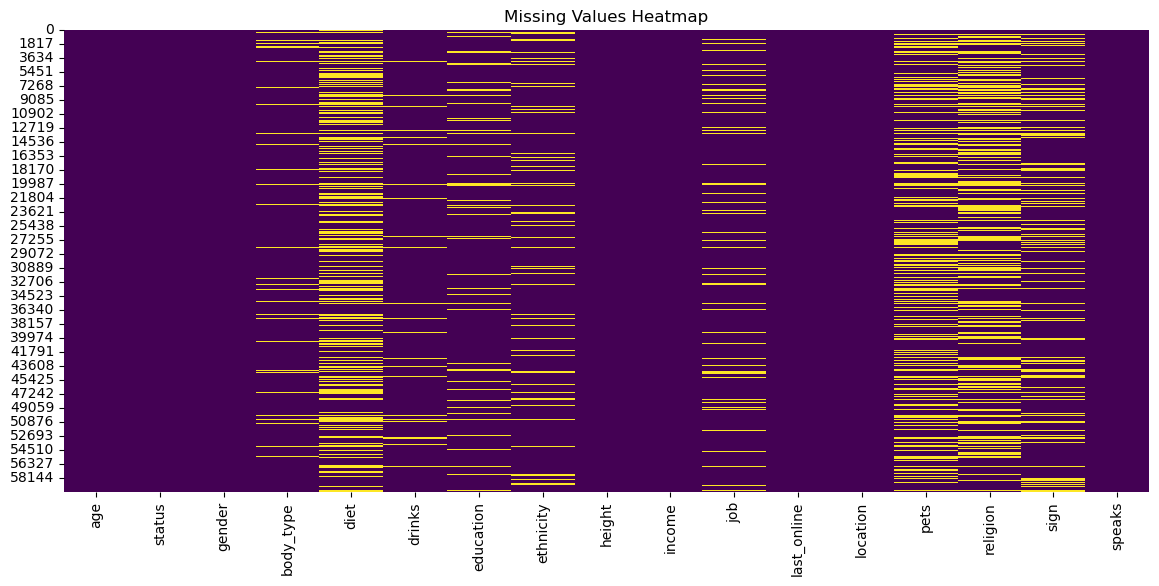

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.show()

In [14]:
### Insight

#The heatmap clearly shows which columns have the highest concentration of missing values.
#Columns with more than 50% missing values will be removed in the next step.

In [15]:
missing_percentage = df.isnull().mean()*100

missing_percentage[missing_percentage > 50]

Series([], dtype: float64)

In [16]:
columns_to_drop = missing_percentage[missing_percentage > 50].index

df.drop(columns=columns_to_drop, inplace=True)

In [17]:
df.columns

Index(['age', 'status', 'gender', 'body_type', 'diet', 'drinks', 'education',
       'ethnicity', 'height', 'income', 'job', 'last_online', 'location',
       'pets', 'religion', 'sign', 'speaks'],
      dtype='object')

In [18]:
### Observation

#Columns with more than 50% missing values were removed because they contained insufficient data for reliable analysis.

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.drop_duplicates(inplace=True)

In [21]:
df.dtypes

age              int64
status          object
gender          object
body_type       object
diet            object
drinks          object
education       object
ethnicity       object
height         float64
income           int64
job             object
last_online     object
location        object
pets            object
religion        object
sign            object
speaks          object
dtype: object

In [22]:
df['last_online'].head(10)

0    2012-06-28-20-30
1    2012-06-29-21-41
2    2012-06-27-09-10
3    2012-06-28-14-22
4    2012-06-27-21-26
5    2012-06-29-19-18
6    2012-06-25-20-45
7    2012-06-29-12-30
8    2012-06-29-23-39
9    2012-06-28-21-08
Name: last_online, dtype: object

In [23]:
df['last_online'].sample(10)

50186    2012-06-23-16-17
2945     2012-06-29-23-53
48266    2011-09-12-19-10
4791     2011-11-12-13-50
16185    2012-06-30-13-34
12661    2012-06-02-17-17
2748     2012-05-23-21-45
3620     2012-05-23-16-25
13320    2012-06-02-22-11
6007     2012-05-20-22-49
Name: last_online, dtype: object

In [24]:
df['last_online'] = pd.to_datetime(
    df['last_online'],
    format='%Y-%m-%d-%H-%M',
    errors='coerce'
)

In [25]:
df['last_online'].head()

0   2012-06-28 20:30:00
1   2012-06-29 21:41:00
2   2012-06-27 09:10:00
3   2012-06-28 14:22:00
4   2012-06-27 21:26:00
Name: last_online, dtype: datetime64[ns]

In [26]:
df['last_online'].dtype

dtype('<M8[ns]')

In [27]:
reference_date = df['last_online'].max()

df['days_since_last_online'] = (
    reference_date - df['last_online']
).dt.days

In [29]:
bins = [18, 25, 35, 45, 100]
labels = ['18-25', '26-35', '36-45', '46+']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

In [30]:
df[['age', 'age_group']].head(10)

,age,age_group
0,22,18-25
1,35,26-35
2,38,36-45
3,23,18-25
4,29,26-35
5,29,26-35
6,32,26-35
7,31,26-35
8,24,18-25
9,37,36-45


In [31]:
income_nonzero = df.loc[df['income'] > 0, 'income']

q1 = income_nonzero.quantile(0.25)
q3 = income_nonzero.quantile(0.75)

def income_category(x):
    if x == 0:
        return 'Not Reported'
    elif x <= q1:
        return 'Low Income'
    elif x <= q3:
        return 'Medium Income'
    else:
        return 'High Income'

df['income_group'] = df['income'].apply(income_category)

In [32]:
df['income_group'].value_counts()

income_group
Low Income       51394
Medium Income     7203
High Income       1349
Name: count, dtype: int64

In [33]:
df['profile_completeness'] = (df.notnull().sum(axis=1) / len(df.columns)) * 100

In [34]:
df['profile_completeness'].head()

0    100.0
1    100.0
2     85.0
3     95.0
4     90.0
Name: profile_completeness, dtype: float64

In [35]:
df['height_cm'] = df['height'] * 2.54

In [36]:
df[['height', 'height_cm']].head()

,height,height_cm
0,75.0,190.50
1,70.0,177.80
2,68.0,172.72
3,71.0,180.34
4,66.0,167.64


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['age_scaled', 'height_scaled', 'income_scaled']] = scaler.fit_transform(
    df[['age', 'height', 'income']]
)

In [38]:
## Gender Distribution

#This analysis helps understand the proportion of male and female users on the Bumble platform.

In [39]:
df['gender'].value_counts()

gender
m    35829
f    24117
Name: count, dtype: int64

In [40]:
(df['gender'].value_counts(normalize=True) * 100).round(2)

gender
m    59.77
f    40.23
Name: proportion, dtype: float64

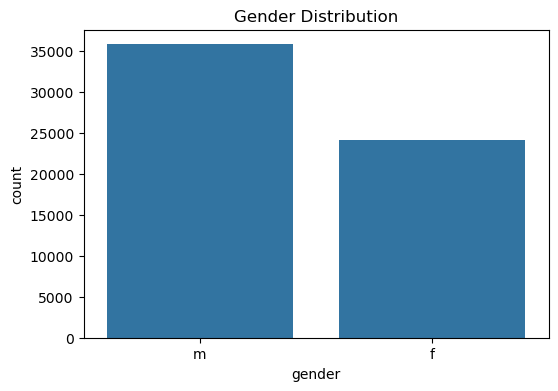

In [41]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='gender')
plt.title("Gender Distribution")
plt.show()

In [42]:
df['status'].value_counts()

status
single            55697
seeing someone     2064
available          1865
married             310
unknown              10
Name: count, dtype: int64

In [43]:
(df['status'].value_counts(normalize=True) * 100).round(2)

status
single            92.91
seeing someone     3.44
available          3.11
married            0.52
unknown            0.02
Name: proportion, dtype: float64

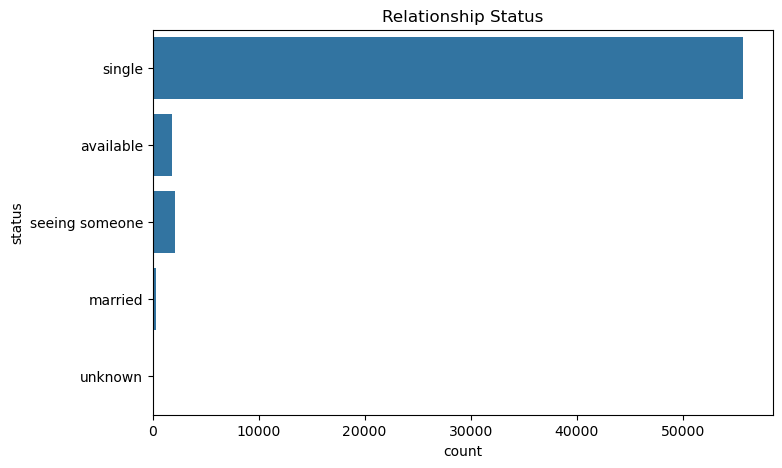

In [44]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, y='status')
plt.title("Relationship Status")
plt.show()

In [45]:
pd.crosstab(df['gender'], df['status'])

status,available,married,seeing someone,single,unknown
gender,,,,,
f,656,135,1003,22319,4
m,1209,175,1061,33378,6


In [46]:
pd.crosstab(
    df['gender'],
    df['status'],
    normalize='index'
) * 100

status,available,married,seeing someone,single,unknown
gender,,,,,
f,2.720073,0.559771,4.158892,92.544678,0.016586
m,3.374362,0.488431,2.961288,93.159173,0.016746


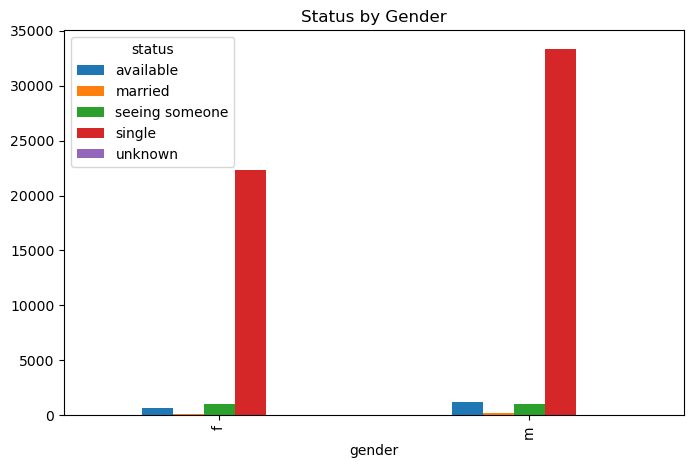

In [47]:
pd.crosstab(df['gender'], df['status']).plot(kind='bar', figsize=(8,5))
plt.title("Status by Gender")
plt.show()

In [48]:
numerical = df[['age', 'height', 'income']]

In [49]:
numerical.corr()

,age,height,income
age,1.000000,-0.022262,-0.001004
height,-0.022262,1.000000,0.065049
income,-0.001004,0.065049,1.000000


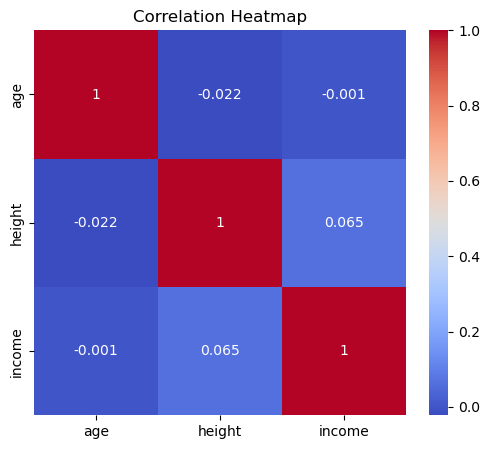

In [50]:
plt.figure(figsize=(6,5))
sns.heatmap(numerical.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [51]:
df['diet'].value_counts()

diet
mostly anything        16585
anything                6183
strictly anything       5113
mostly vegetarian       3444
mostly other            1007
strictly vegetarian      875
vegetarian               667
strictly other           452
mostly vegan             338
other                    331
strictly vegan           228
vegan                    136
mostly kosher             86
mostly halal              48
strictly halal            18
strictly kosher           18
halal                     11
kosher                    11
Name: count, dtype: int64

In [52]:
(df['diet'].value_counts(normalize=True) * 100).round(2)

diet
mostly anything        46.65
anything               17.39
strictly anything      14.38
mostly vegetarian       9.69
mostly other            2.83
strictly vegetarian     2.46
vegetarian              1.88
strictly other          1.27
mostly vegan            0.95
other                   0.93
strictly vegan          0.64
vegan                   0.38
mostly kosher           0.24
mostly halal            0.14
strictly halal          0.05
strictly kosher         0.05
halal                   0.03
kosher                  0.03
Name: proportion, dtype: float64

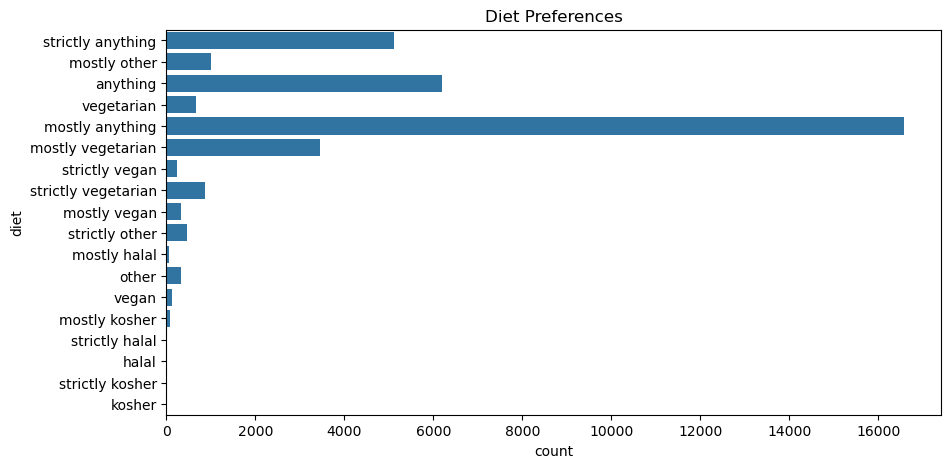

In [53]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='diet')
plt.title("Diet Preferences")
plt.show()

In [54]:
pd.crosstab(df['diet'], df['drinks'])

drinks,desperately,not at all,often,rarely,socially,very often
diet,,,,,,
anything,21,295,574,510,4534,58
halal,0,4,1,0,4,0
kosher,0,1,0,2,7,1
mostly anything,66,842,1386,1537,12277,129
mostly halal,3,10,2,8,16,4
mostly kosher,1,7,4,17,50,5
mostly other,8,91,49,176,646,5
mostly vegan,2,40,22,62,193,3
mostly vegetarian,19,195,233,466,2388,20


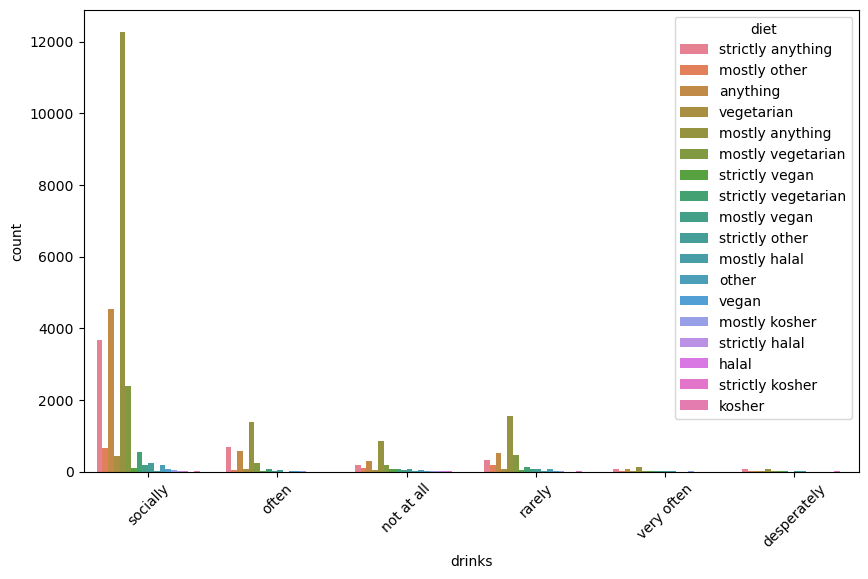

In [55]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='drinks', hue='diet')
plt.xticks(rotation=45)
plt.show()

In [57]:
df['location'].head(10)

0    south san francisco, california
1                oakland, california
2          san francisco, california
3               berkeley, california
4          san francisco, california
5          san francisco, california
6          san francisco, california
7          san francisco, california
8      belvedere tiburon, california
9              san mateo, california
Name: location, dtype: object

In [58]:
df['location'].sample(10)

13797          san francisco, california
12654          san francisco, california
49051              san mateo, california
8440           san francisco, california
9117           san francisco, california
21543    south san francisco, california
38428              san pablo, california
3870               san mateo, california
45244               richmond, california
10061          san francisco, california
Name: location, dtype: object

In [59]:
df[['city', 'state']] = df['location'].str.rsplit(',', n=1, expand=True)

In [60]:
df['city'] = df['city'].str.strip()
df['state'] = df['state'].str.strip()

In [61]:
df[['location', 'city', 'state']].head(10)

,location,city,state
0,"south san francisco, california",south san francisco,california
1,"oakland, california",oakland,california
2,"san francisco, california",san francisco,california
3,"berkeley, california",berkeley,california
4,"san francisco, california",san francisco,california
5,"san francisco, california",san francisco,california
6,"san francisco, california",san francisco,california
7,"san francisco, california",san francisco,california
8,"belvedere tiburon, california",belvedere tiburon,california
9,"san mateo, california",san mateo,california


In [62]:
df['location'].str.count(',').value_counts()

location
1    59945
2        1
Name: count, dtype: int64

In [63]:
df['city'].value_counts().head(5)

city
san francisco    31064
oakland           7214
berkeley          4212
san mateo         1331
palo alto         1064
Name: count, dtype: int64

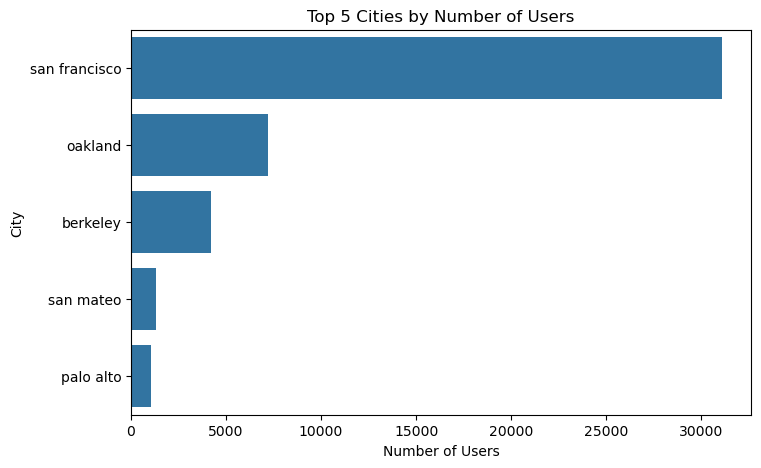

In [64]:
top_cities = df['city'].value_counts().head(5)

plt.figure(figsize=(8,5))
sns.barplot(x=top_cities.values, y=top_cities.index)

plt.title("Top 5 Cities by Number of Users")
plt.xlabel("Number of Users")
plt.ylabel("City")
plt.show()

In [65]:
df['state'].value_counts().head(5)

state
california       59855
new york            17
illinois             8
massachusetts        5
texas                4
Name: count, dtype: int64

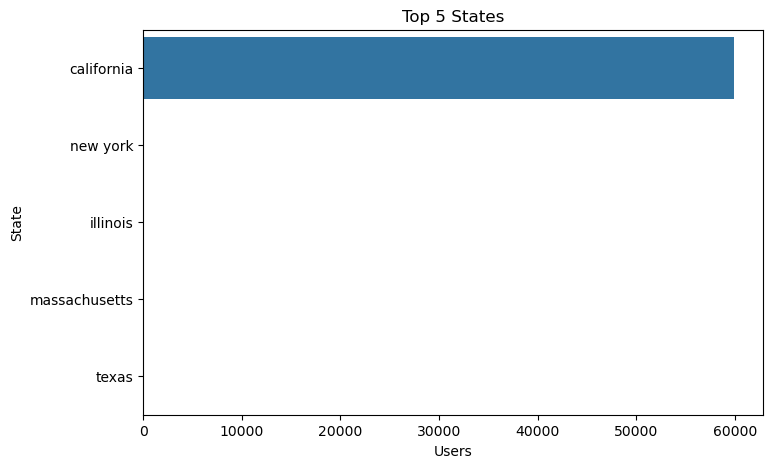

In [66]:
top_states = df['state'].value_counts().head(5)

plt.figure(figsize=(8,5))
sns.barplot(x=top_states.values, y=top_states.index)

plt.title("Top 5 States")
plt.xlabel("Users")
plt.ylabel("State")
plt.show()

In [67]:
df.groupby('city')['age'].mean().sort_values(ascending=False).head()

city
forest knolls     62.5
bellingham        59.0
port costa        53.0
seaside           50.0
redwood shores    47.0
Name: age, dtype: float64

In [68]:
df.groupby('state')['income'].mean().sort_values(ascending=False).head()

state
new jersey      150000.0
colorado         74999.5
vietnam          60000.0
canada           60000.0
pennsylvania     40000.0
Name: income, dtype: float64

In [69]:
df.groupby('gender')['height_cm'].mean()

gender
f    165.363837
m    178.926471
Name: height_cm, dtype: float64

In [70]:
df.groupby('age_group')['height_cm'].mean()

C:\Users\Dell\AppData\Local\Temp\ipykernel_356\2991845816.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['height_cm'].mean()


age_group
18-25    173.289992
26-35    173.753484
36-45    173.545741
46+      172.558763
Name: height_cm, dtype: float64

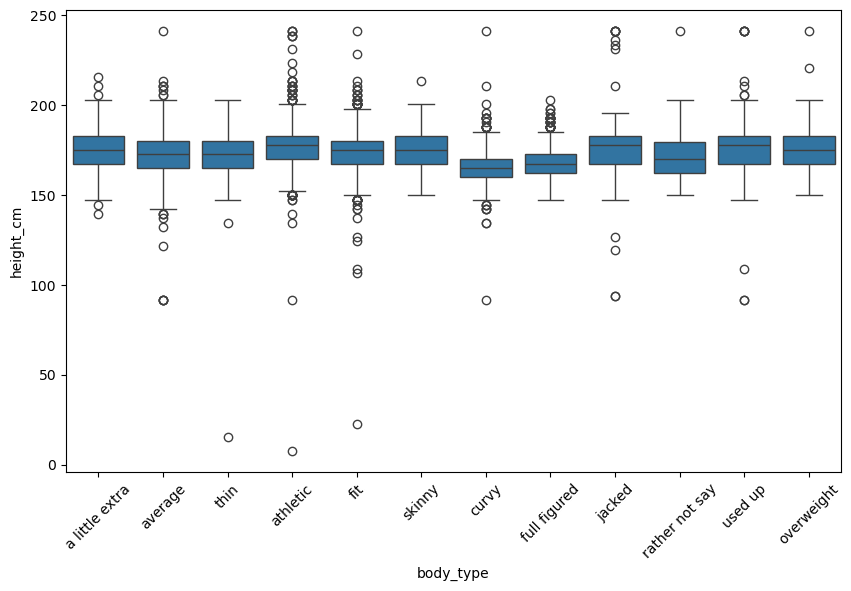

In [71]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='body_type', y='height_cm')

plt.xticks(rotation=45)
plt.show()

In [72]:
income_df = df[df['income'] > 0]

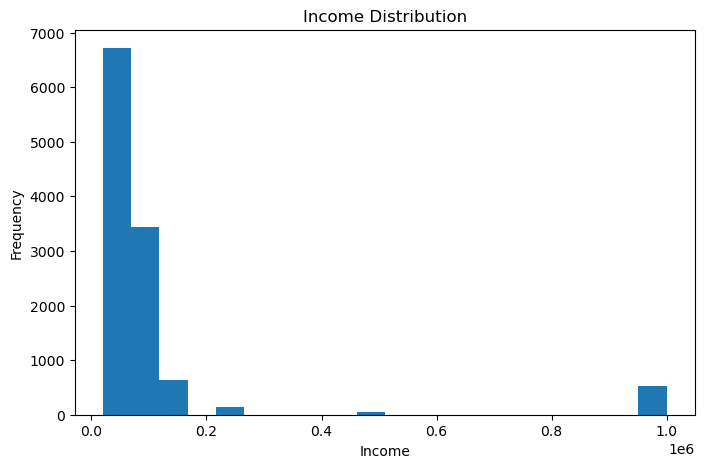

In [73]:
plt.figure(figsize=(8,5))
plt.hist(income_df['income'], bins=20)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")

plt.show()

In [74]:
income_df.groupby('age_group')['income'].median()

C:\Users\Dell\AppData\Local\Temp\ipykernel_356\1981646879.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_df.groupby('age_group')['income'].median()


age_group
18-25    20000.0
26-35    50000.0
36-45    80000.0
46+      80000.0
Name: income, dtype: float64

In [75]:
income_df.groupby('gender')['income'].median()

gender
f    40000.0
m    60000.0
Name: income, dtype: float64

In [76]:
income_df.groupby(['gender','status'])['income'].median()

gender  status        
f       available         30000.0
        married           30000.0
        seeing someone    20000.0
        single            40000.0
        unknown           20000.0
m       available         60000.0
        married           60000.0
        seeing someone    40000.0
        single            60000.0
Name: income, dtype: float64

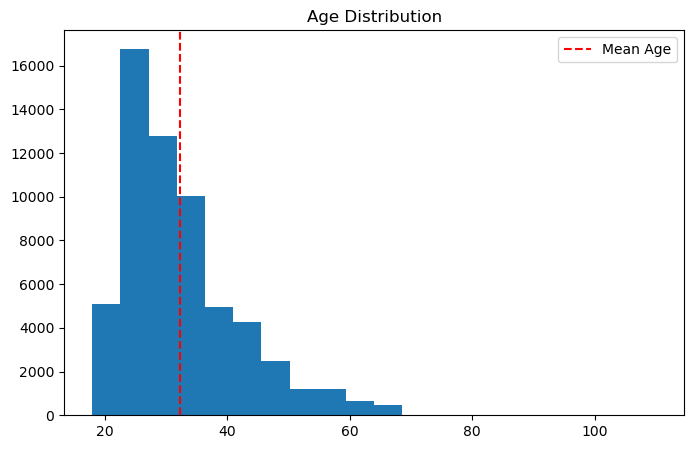

In [77]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=20)

plt.axvline(df['age'].mean(),
            color='red',
            linestyle='--',
            label='Mean Age')

plt.legend()
plt.title("Age Distribution")

plt.show()

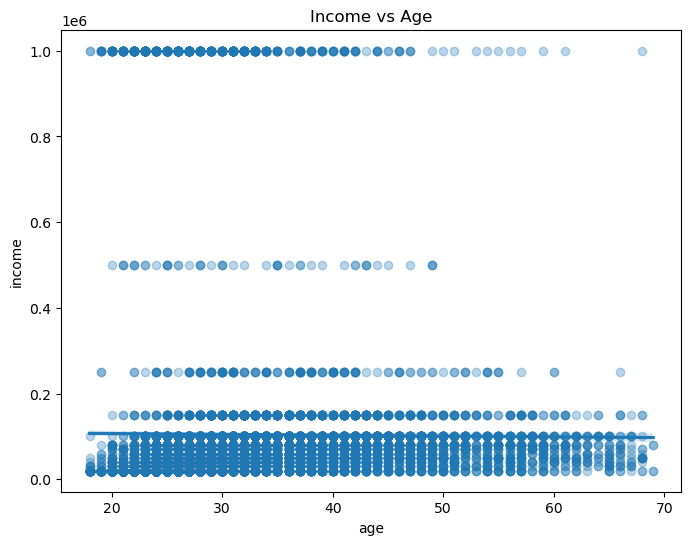

In [78]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=income_df,
    x='age',
    y='income',
    scatter_kws={'alpha':0.3}
)

plt.title("Income vs Age")

plt.show()

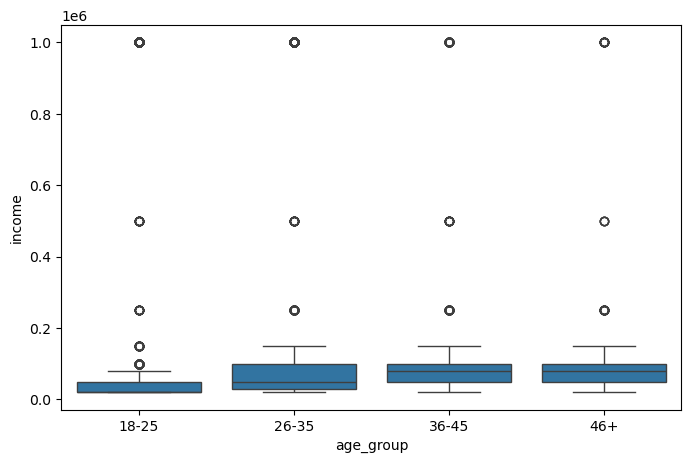

In [79]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=income_df,
    x='age_group',
    y='income'
)

plt.show()

In [80]:
df['pets'].value_counts()

pets
likes dogs and likes cats          14814
likes dogs                          7224
likes dogs and has cats             4313
has dogs                            4134
has dogs and likes cats             2333
likes dogs and dislikes cats        2029
has dogs and has cats               1474
has cats                            1406
likes cats                          1063
has dogs and dislikes cats           552
dislikes dogs and likes cats         240
dislikes dogs and dislikes cats      196
dislikes cats                        122
dislikes dogs and has cats            81
dislikes dogs                         44
Name: count, dtype: int64

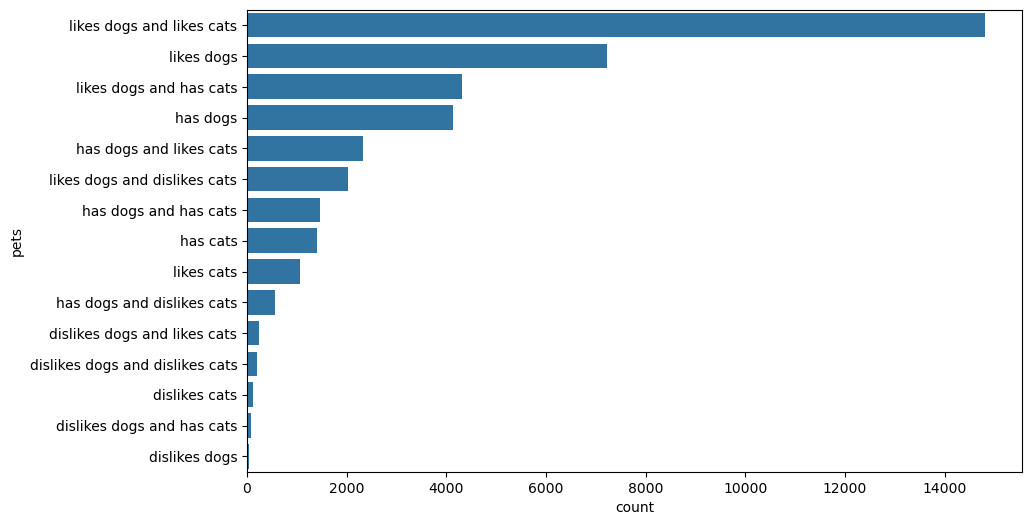

In [81]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y='pets',
    order=df['pets'].value_counts().index
)

plt.show()

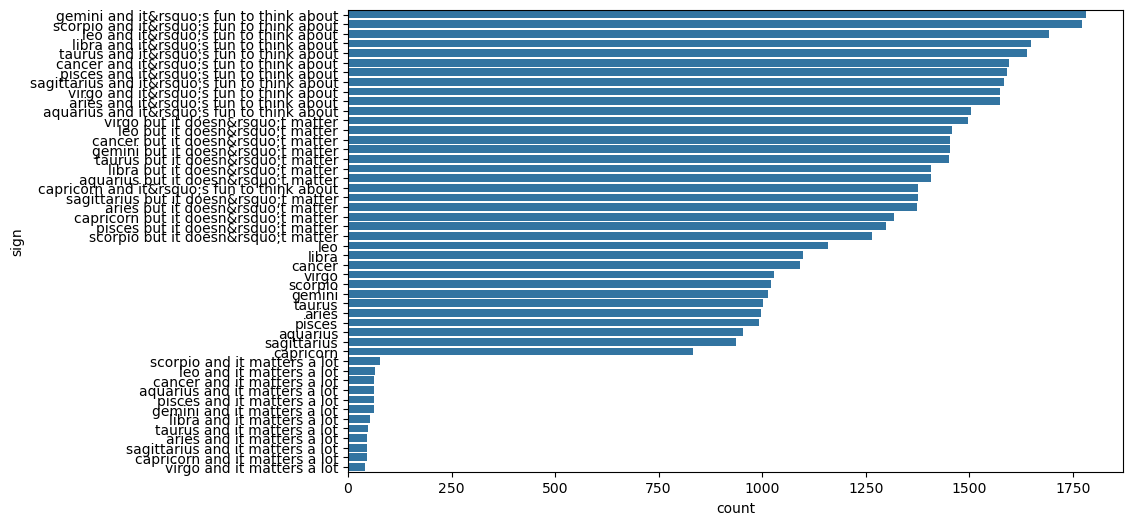

In [82]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y='sign',
    order=df['sign'].value_counts().index
)

plt.show()